In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pygpcca as gp

In [31]:
import networkx as nx
import itertools as it

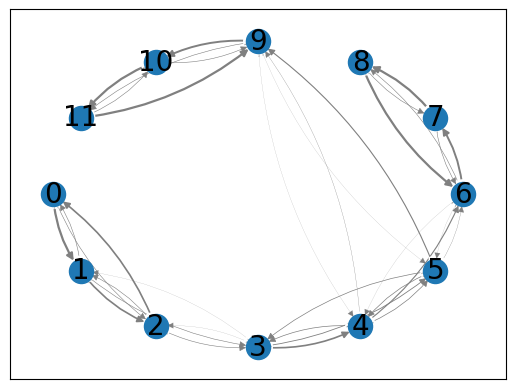

In [75]:
def draw_labeled_multigraph(G, attr_name, ax=None):
    """
    Length of connectionstyle must be at least that of a maximum number of edges
    between pair of nodes. This number is maximum one-sided connections
    for directed graph and maximum total connections for undirected graph.
    """
    # Works with arc3 and angle3 connectionstyles
    connectionstyle = [f"arc3,rad={r}" for r in it.accumulate([0.15] * 4)]
    # connectionstyle = [f"angle3,angleA={r}" for r in it.accumulate([30] * 4)]

    pos = nx.shell_layout(G)
    nx.draw_networkx_nodes(G, pos, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=20, ax=ax)
    nx.draw_networkx_edges(
        G, pos, edge_color="grey", connectionstyle=connectionstyle, ax=ax, width=[v * 2 for v in nx.get_edge_attributes(G, "weight").values()]
    )
    
    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=None,
        # labels,
        connectionstyle=connectionstyle,
        font_size=0,
        label_pos=0.0,
        # font_color="blue",
        # bbox={"alpha": 0},
        ax=ax,
    )


draw_labeled_multigraph(nx.from_numpy_array(P, create_using=nx.DiGraph, edge_attr="weight"), None)

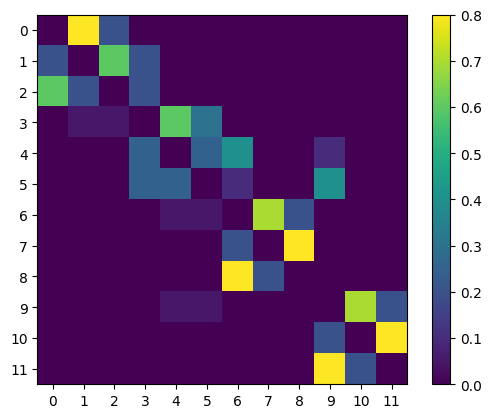

In [2]:
P = np.array(
    [
    # 0.   1.   2.   3.   4.   5.   6.   7.   8.   9.   10.  11.
    [0.0, 0.8, 0.2, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], #0
    [0.2, 0.0, 0.6, 0.2, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], #1
    [0.6, 0.2, 0.0, 0.2, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], #2

    [0.0, 0.05, 0.05, 0.0, 0.6, 0.3, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], #3
    [0.0, 0.0, 0.0, 0.25, 0.0, 0.25, 0.4, 0.0, 0.0, 0.1, 0.0, 0.0], #4
    [0.0, 0.0, 0.0, 0.25, 0.25, 0.0, 0.1, 0.0, 0.0, 0.4, 0.0, 0.0], #5

    [0.0, 0.0, 0.0, 0.0, 0.05, 0.05, 0.0, 0.7, 0.2, 0.0, 0.0, 0.0], #6
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.2, 0.0, 0.8, 0.0, 0.0, 0.0], #7
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.8, 0.2, 0.0, 0.0, 0.0, 0.0], #8

    [0.0, 0.0, 0.0, 0.0, 0.05, 0.05, 0.0, 0.0, 0.0, 0.0, 0.7, 0.2], #9
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.2, 0.0, 0.8], #10
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.8, 0.2, 0.0], #11
    ],
    dtype=np.float64,
)

# plot the matrix P:
fig, ax = plt.subplots()
c = ax.imshow(P)
plt.xticks(np.arange(P.shape[1]))
plt.yticks(np.arange(P.shape[0]))
plt.ylim(-0.5, P.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()

In [3]:
gpcca = gp.GPCCA(P, z='LM', method='brandts')

In [4]:
gpcca.minChi(2, 12)

[-4.1934977103007952e-16,
 -1.9115148688076595e-16,
 -0.9923508699724521,
 -0.9972757370249482,
 -0.9268025769045111,
 -0.2705117206956659,
 -0.33604479452159314,
 -0.29730361863062443,
 -0.29104047575515446,
 -0.4290220820189277,
 -2.8713122684952326e-16]

In [7]:
gpcca.optimize({'m_min':2, 'm_max':12})

/home/kushal/venvs/fpl/lib/python3.11/site-packages/pygpcca/_gpcca.py:1024: UserWarning: Clustering into 4 clusters will split complex conjugate eigenvalues. Skipping clustering into 4 clusters.
  warnings.warn(
/home/kushal/venvs/fpl/lib/python3.11/site-packages/pygpcca/_gpcca.py:1024: UserWarning: Clustering into 6 clusters will split complex conjugate eigenvalues. Skipping clustering into 6 clusters.
  warnings.warn(
/home/kushal/venvs/fpl/lib/python3.11/site-packages/pygpcca/_gpcca.py:1024: UserWarning: Clustering into 9 clusters will split complex conjugate eigenvalues. Skipping clustering into 9 clusters.
  warnings.warn(
/home/kushal/venvs/fpl/lib/python3.11/site-packages/pygpcca/_gpcca.py:1058: UserWarning: Clustering 12 data points into 12 clusters is always perfectly crisp. Thus m=12 won't be included in the search for the optimal cluster number.
  warnings.warn(


GPCCA[n=12, n_macrostates=3]

In [8]:
gpcca.crispness_values

array([0.74151472, 0.81512805, 0.        , 0.38587154, 0.        ,
       0.41628049, 0.41788963, 0.        , 0.55513151, 0.53758366,
       1.        ])

In [9]:
gpcca.optimal_crispness

0.8151280474517892

In [10]:
gpcca.n_m

3

In [11]:
gpcca.top_eigenvalues

array([ 1.        +0.j        ,  0.96554293+0.j        ,
        0.88404279+0.j        , -0.48277146+0.48908574j,
       -0.48277146-0.48908574j, -0.49366905+0.47392788j,
       -0.49366905-0.47392788j,  0.58853656+0.j        ,
       -0.43198962+0.39030468j, -0.43198962-0.39030468j,
       -0.37126202+0.j        , -0.25      +0.j        ])

In [12]:
gpcca.dominant_eigenvalues

array([1.        +0.j, 0.96554293+0.j, 0.88404279+0.j])

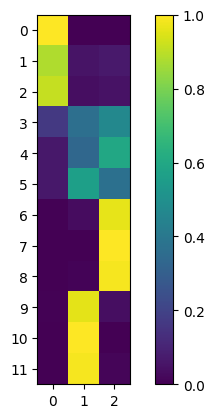

array([[1.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [8.80009662e-01, 5.26338400e-02, 6.73564979e-02],
       [9.12351139e-01, 3.84758290e-02, 4.91730323e-02],
       [1.64953404e-01, 3.67067094e-01, 4.67979502e-01],
       [6.51588802e-02, 3.35927186e-01, 5.98913934e-01],
       [6.51588802e-02, 5.64708356e-01, 3.70132763e-01],
       [5.02066367e-03, 3.27724659e-02, 9.62206870e-01],
       [2.43667499e-16, 2.66751396e-17, 1.00000000e+00],
       [1.78878958e-03, 1.11025375e-02, 9.87108673e-01],
       [5.02066367e-03, 9.59750248e-01, 3.52290885e-02],
       [0.00000000e+00, 1.00000000e+00, 1.70817577e-17],
       [1.78878958e-03, 9.86286754e-01, 1.19244563e-02]])

In [13]:
chi = gpcca.memberships
# plot chi:
fig, ax = plt.subplots()
c = ax.imshow(chi)
plt.xticks(np.arange(chi.shape[1]))
plt.yticks(np.arange(chi.shape[0]))
plt.ylim(-0.5, chi.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()
# show chi matrix:
chi

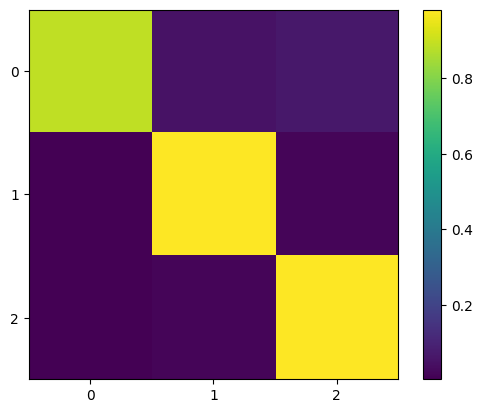

array([[0.88647796, 0.04980224, 0.0637198 ],
       [0.00243516, 0.98097945, 0.01658538],
       [0.00243516, 0.01543652, 0.98212831]])

In [14]:
P_c = gpcca.coarse_grained_transition_matrix
# plot P_c:
fig, ax = plt.subplots()
c = ax.imshow(P_c)
plt.xticks(np.arange(P_c.shape[1]))
plt.yticks(np.arange(P_c.shape[0]))
plt.ylim(-0.5, P_c.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()
# show P_c matrix:
P_c

In [15]:
gpcca.input_distribution

array([0.08333333, 0.08333333, 0.08333333, 0.08333333, 0.08333333,
       0.08333333, 0.08333333, 0.08333333, 0.08333333, 0.08333333,
       0.08333333, 0.08333333])

In [16]:
gpcca.coarse_grained_input_distribution

array([0.25843757, 0.36239369, 0.37916873])

In [17]:
gpcca.macrostate_assignment

array([0, 0, 0, 2, 2, 1, 2, 2, 2, 1, 1, 1])

In [18]:
gpcca.rotation_matrix

array([[ 0.25843757,  0.36239369,  0.37916873],
       [ 0.03366022, -0.36112468,  0.32746445],
       [-0.39024389,  0.164552  ,  0.22569189]])

<Axes: >

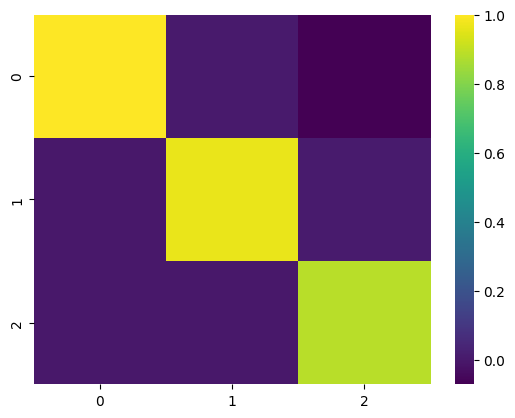

In [24]:
sns.heatmap(gpcca.schur_matrix, cmap="viridis")

In [21]:
import seaborn as sns

<Axes: >

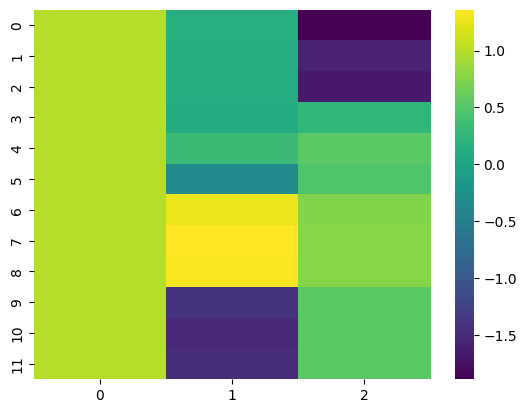

In [25]:
sns.heatmap(gpcca.schur_vectors, cmap="viridis")

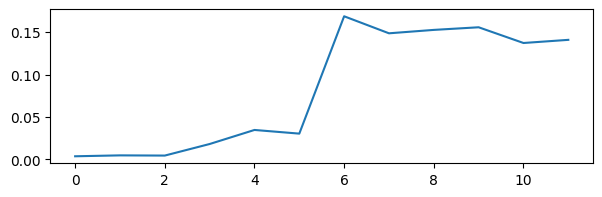

In [28]:
plt.figure(figsize=(7, 2))
plt.plot(gpcca.stationary_probability)

In [29]:
gpcca.coarse_grained_stationary_probability

array([0.02100054, 0.46893777, 0.51006168])